# Checkpoint 3 — Clustering e segmentação de clientes

**Disciplina: Modelagem Linear para Aprendizado de Máquina**  
**Atividade prática em Python | K-Means, Elbow e Silhouette Score**

**Nome(s) e RM(s):** Gabriel Rodrigues Zappelloni — RM 572060  
**Turma:** preencha aqui.

## Situação-problema

Uma empresa de comércio eletrônico deseja conhecer os diferentes perfis de compra de seus clientes para planejar ações de relacionamento. Cada registro reúne o histórico de um cliente nos últimos 12 meses, calculado na mesma data de referência.

Seu desafio é identificar grupos de clientes com comportamentos semelhantes, justificar a quantidade de clusters e propor uma ação coerente para cada perfil encontrado.

Não há uma coluna com a classificação correta. A qualidade da análise depende da preparação dos dados, das evidências apresentadas e da interpretação dos agrupamentos.

## O que desenvolver

1. Explorar a base e selecionar as variáveis.
2. Padronizar as variáveis numéricas.
3. Aplicar K-Means e investigar diferentes valores de **k**.
4. Construir os gráficos de **Elbow** e **Silhouette Score**.
5. Justificar o k escolhido, visualizar os grupos e interpretar seus perfis.
6. Apresentar conclusões e limitações da análise.

As células de importação e leitura estão prontas. Complete as demais células de código e os espaços de resposta. Execute o notebook na ordem, mantendo os resultados visíveis.


## 1. Conheça a base

Esta base contém **120 clientes fictícios**. Os dados foram gerados previamente com NumPy e semente 303, para fins didáticos, e estão incorporados neste notebook como texto CSV. **Não foram coletados de pessoas, empresas ou bases públicas.** A célula de leitura apenas carrega os dados; não gera novos valores.

| Coluna | Significado | Unidade / uso |
| --- | --- | --- |
| `id_cliente` | Identificador fictício do cliente | Identificação; excluir do modelo |
| `gasto_total_12_meses` | Soma dos valores das compras nos últimos 12 meses | R$ |
| `quantidade_compras_12_meses` | Número de compras realizadas nos últimos 12 meses | Compras |
| `dias_desde_ultima_compra` | Dias entre a compra mais recente e a data de referência | Dias |

O gasto descreve o valor acumulado; a quantidade informa a frequência de compras; o tempo desde a última compra representa a recência. Um valor menor de dias indica uma compra mais recente.

Clientes com gasto semelhante podem ter quantidades de compras e recências diferentes. Essas medidas não informam renda, satisfação ou o motivo de um cliente deixar de comprar.

Não substitua a base. Use as três variáveis numéricas no agrupamento principal.


In [1]:
# Bibliotecas utilizadas na atividade.
from io import StringIO
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

plt.rcParams['figure.figsize'] = (9, 5)


In [2]:
# Base simulada incorporada ao notebook: não é necessário baixar um CSV.
DADOS_CSV = """
id_cliente,gasto_total_12_meses,quantidade_compras_12_meses,dias_desde_ultima_compra
CL001,2415.04,22,14
CL002,6136.88,7,87
CL003,8520.86,31,16
CL004,712.95,1,132
CL005,7964.46,6,104
CL006,897.35,5,99
CL007,606.06,6,108
CL008,8132.06,10,98
CL009,8992.43,30,9
CL010,8439.0,32,4
CL011,3086.0,21,14
CL012,3505.35,17,28
CL013,3824.73,17,18
CL014,14019.61,19,14
CL015,2114.77,23,21
CL016,1161.25,2,122
CL017,6691.19,7,78
CL018,7312.2,4,95
CL019,711.17,5,177
CL020,8414.07,26,0
CL021,7911.54,6,38
CL022,2076.62,22,12
CL023,8985.03,6,45
CL024,7249.79,5,99
CL025,5784.63,8,82
CL026,7510.04,24,14
CL027,996.41,2,147
CL028,3031.75,25,19
CL029,648.73,4,51
CL030,533.45,5,50
CL031,9298.68,6,74
CL032,7208.79,22,10
CL033,6105.18,6,84
CL034,2043.65,26,15
CL035,6791.38,7,50
CL036,554.34,3,95
CL037,8296.09,44,16
CL038,2567.37,16,12
CL039,9130.6,26,13
CL040,3430.01,30,19
CL041,8305.2,34,9
CL042,5551.75,7,58
CL043,7431.23,10,58
CL044,1006.79,6,57
CL045,6493.35,6,90
CL046,5545.24,11,92
CL047,3131.7,25,7
CL048,2725.2,24,11
CL049,1024.4,5,60
CL050,825.75,4,66
CL051,5015.92,4,80
CL052,2768.34,19,34
CL053,6684.99,7,54
CL054,3195.3,30,9
CL055,10387.5,30,12
CL056,876.94,6,54
CL057,624.05,5,104
CL058,956.59,3,167
CL059,12263.9,32,14
CL060,1183.14,2,109
CL061,6823.82,5,42
CL062,6533.72,6,80
CL063,11253.35,27,0
CL064,7448.21,23,8
CL065,1053.25,4,110
CL066,5618.55,19,10
CL067,2422.63,20,28
CL068,8860.03,31,9
CL069,11409.28,24,12
CL070,2554.03,26,16
CL071,648.36,2,64
CL072,1625.9,18,13
CL073,924.97,5,98
CL074,806.85,5,155
CL075,11288.98,24,12
CL076,5693.5,2,86
CL077,2157.1,25,10
CL078,6570.68,7,37
CL079,2288.58,20,13
CL080,420.04,5,89
CL081,7737.84,16,22
CL082,7535.89,5,25
CL083,8534.53,19,15
CL084,6270.62,7,137
CL085,5923.75,26,23
CL086,1154.26,6,122
CL087,4933.71,7,90
CL088,658.41,4,151
CL089,10109.2,20,7
CL090,9140.44,32,0
CL091,7116.95,7,103
CL092,2173.18,25,5
CL093,6307.09,7,67
CL094,4787.96,5,65
CL095,715.66,3,79
CL096,12276.45,23,8
CL097,7253.65,27,14
CL098,710.74,5,130
CL099,9069.7,4,65
CL100,3510.14,24,14
CL101,940.47,3,111
CL102,2393.85,30,21
CL103,5512.15,5,106
CL104,2574.35,23,6
CL105,8571.63,19,7
CL106,2021.96,22,8
CL107,3505.47,7,16
CL108,2254.15,25,18
CL109,701.64,4,38
CL110,2018.77,32,10
CL111,2920.7,21,18
CL112,1120.58,5,86
CL113,1339.64,3,108
CL114,3017.75,28,5
CL115,9374.86,29,12
CL116,485.39,4,132
CL117,6896.28,25,10
CL118,8717.02,42,10
CL119,10309.74,28,16
CL120,2676.42,17,12
"""
df = pd.read_csv(StringIO(DADOS_CSV))
print(df.head().to_string(index=False))
print(f"Clientes: {len(df)}")


id_cliente  gasto_total_12_meses  quantidade_compras_12_meses  dias_desde_ultima_compra
     CL001               2415.04                           22                        14
     CL002               6136.88                            7                        87
     CL003               8520.86                           31                        16
     CL004                712.95                            1                       132
     CL005               7964.46                            6                       104
Clientes: 120


## 2. Exploração dos dados — 1,0 ponto

Apresente o tamanho da base, os tipos das colunas, a quantidade de valores ausentes e as estatísticas descritivas das três variáveis numéricas. Verifique se os identificadores se repetem.

Responda: quais variáveis apresentam maior amplitude? Por que usar apenas o gasto total poderia esconder diferenças de comportamento?


In [3]:
# Tamanho da base, tipos, ausentes e duplicidade de identificadores
print("Formato (linhas, colunas):", df.shape)
print()
df.info()
print()
print("Valores ausentes por coluna:")
print(df.isna().sum())
print()
print("Identificadores repetidos:", df['id_cliente'].duplicated().sum())
print("Linhas completamente duplicadas:", df.duplicated().sum())

Formato (linhas, colunas): (120, 4)

<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 4 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id_cliente                   120 non-null    str    
 1   gasto_total_12_meses         120 non-null    float64
 2   quantidade_compras_12_meses  120 non-null    int64  
 3   dias_desde_ultima_compra     120 non-null    int64  
dtypes: float64(1), int64(2), str(1)
memory usage: 3.9 KB

Valores ausentes por coluna:
id_cliente                     0
gasto_total_12_meses           0
quantidade_compras_12_meses    0
dias_desde_ultima_compra       0
dtype: int64

Identificadores repetidos: 0
Linhas completamente duplicadas: 0


In [4]:
# Estatísticas descritivas e amplitude das três variáveis numéricas
variaveis = ['gasto_total_12_meses', 'quantidade_compras_12_meses', 'dias_desde_ultima_compra']

descricao = df[variaveis].describe().T
descricao['amplitude'] = descricao['max'] - descricao['min']
descricao['coef_variacao'] = descricao['std'] / descricao['mean']
descricao.round(2)

,count,mean,std,min,25%,50%,75%,max,amplitude,coef_variacao
gasto_total_12_meses,120.0,4829.03,3465.47,420.04,1554.34,4306.34,7516.50,14019.61,13599.57,0.72
quantidade_compras_12_meses,120.0,14.97,10.81,1.00,5.00,10.50,24.25,44.00,43.00,0.72
dias_desde_ultima_compra,120.0,50.93,45.41,0.00,12.00,31.00,87.50,177.00,177.00,0.89


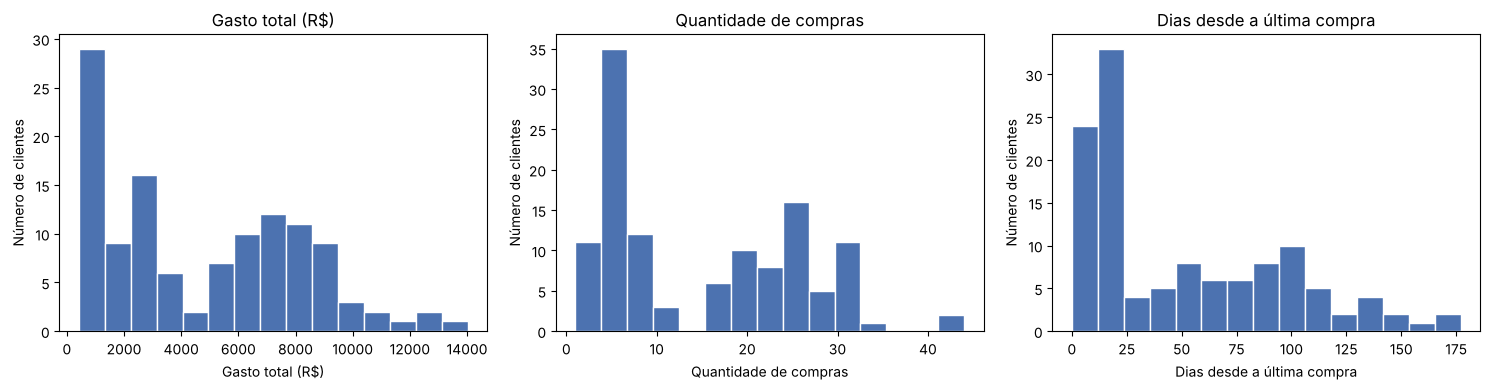

,gasto_total_12_meses,quantidade_compras_12_meses,dias_desde_ultima_compra
gasto_total_12_meses,1.00,0.40,-0.41
quantidade_compras_12_meses,0.40,1.00,-0.79
dias_desde_ultima_compra,-0.41,-0.79,1.00


In [5]:
# Distribuição de cada variável
fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
rotulos_eixos = ['Gasto total (R$)', 'Quantidade de compras', 'Dias desde a última compra']
for eixo, coluna, rotulo in zip(eixos, variaveis, rotulos_eixos):
    eixo.hist(df[coluna], bins=15, color='#4C72B0', edgecolor='white')
    eixo.set_title(rotulo)
    eixo.set_xlabel(rotulo)
    eixo.set_ylabel('Número de clientes')
plt.tight_layout()
plt.show()

# Correlação entre as variáveis
df[variaveis].corr().round(2)

**Resposta e observações:**

- A base tem **120 linhas e 4 colunas**: `id_cliente` (texto), `gasto_total_12_meses` (float), `quantidade_compras_12_meses` e `dias_desde_ultima_compra` (inteiros).
- **Não há valores ausentes** e **nenhum `id_cliente` se repete**, então cada linha é um cliente diferente e não é preciso fazer limpeza.
- **Amplitude:** o gasto total vai de R$ 420,04 a R$ 14.019,61 (amplitude de **R$ 13.599,57**), muito maior em números absolutos que a quantidade de compras (1 a 44, amplitude **43**) e os dias desde a última compra (0 a 177, amplitude **177**). Em termos relativos, a recência é a variável mais dispersa (coeficiente de variação 0,89, contra 0,72 das outras duas).
- As distribuições não são simétricas: a quantidade de compras e a recência têm medianas (10,5 compras e 31 dias) bem diferentes das médias (14,97 e 50,93), sinal de grupos distintos na base.
- **Correlações:** quantidade de compras e recência têm correlação forte e negativa (−0,79): quem compra mais vezes costuma ter comprado há menos tempo. O gasto tem correlação apenas moderada com as outras duas (0,40 e −0,41).

**Por que usar só o gasto total esconderia diferenças?** Como o gasto se relaciona só moderadamente com frequência e recência, clientes com o mesmo gasto podem ter comportamentos opostos. Por exemplo, **CL023** (R$ 8.985,03, 6 compras, 45 dias) e **CL009** (R$ 8.992,43, 30 compras, 9 dias) gastaram quase o mesmo valor, mas o primeiro faz poucas compras grandes e está há mais tempo sem comprar, enquanto o segundo compra com frequência e recentemente. Uma segmentação só pelo gasto colocaria os dois juntos e trataria os dois da mesma forma.


## 3. Preparação e padronização — 1,5 ponto

Crie `X` com as três variáveis numéricas, preservando `df` nas unidades originais. Use `StandardScaler` para criar `X_padronizado`.

Como as escalas diferem, uma variável pode dominar as distâncias. O `StandardScaler` centraliza e divide pelo desvio padrão; ele não converte os dados para o intervalo de 0 a 1. Explique por que essa transformação é pertinente neste problema.

**Cuidado:** não inclua `id_cliente` nem os rótulos dos clusters entre as variáveis do modelo. Use a mesma matriz padronizada para ajustar e avaliar os agrupamentos.


In [6]:
# X recebe apenas as três variáveis numéricas (sem id_cliente)
X = df[variaveis].copy()

scaler = StandardScaler()
X_padronizado = scaler.fit_transform(X)

# Conferência: média ~0 e desvio padrão ~1 em cada coluna; df continua nas unidades originais
conferencia = pd.DataFrame(X_padronizado, columns=variaveis).describe().loc[['mean', 'std', 'min', 'max']]
print("Variáveis padronizadas:")
print(conferencia.round(3).to_string())
print()
print("Médias e desvios usados pelo scaler (unidades originais):")
print(pd.DataFrame({'media': scaler.mean_, 'desvio': scaler.scale_}, index=variaveis).round(2).to_string())
print()
print("df preservado:")
print(df.head(3).to_string(index=False))

Variáveis padronizadas:
      gasto_total_12_meses  quantidade_compras_12_meses  dias_desde_ultima_compra
mean                 0.000                       -0.000                     0.000
std                  1.004                        1.004                     1.004
min                 -1.278                       -1.297                    -1.126
max                  2.663                        2.696                     2.788

Médias e desvios usados pelo scaler (unidades originais):
                               media   desvio
gasto_total_12_meses         4829.03  3451.00
quantidade_compras_12_meses    14.97    10.77
dias_desde_ultima_compra       50.93    45.22

df preservado:
id_cliente  gasto_total_12_meses  quantidade_compras_12_meses  dias_desde_ultima_compra
     CL001               2415.04                           22                        14
     CL002               6136.88                            7                        87
     CL003               8520.86           

**Justificativa da padronização:**

O K-Means agrupa por **distância euclidiana**. Nas unidades originais, uma diferença de R$ 1.000 no gasto pesaria o mesmo que 1.000 compras ou 1.000 dias, o que não faz sentido. Como o desvio padrão do gasto (≈ R$ 3.451) é centenas de vezes maior que o da quantidade de compras (≈ 10,8) e o da recência (≈ 45,2), **o gasto dominaria quase toda a distância** e o modelo, na prática, agruparia só pelo valor gasto, o que é exatamente o que a seção 2 mostrou ser insuficiente.

O `StandardScaler` transforma cada variável em $z = (x - \text{média}) / \text{desvio padrão}$. Depois disso, as três têm média 0 e desvio 1 (conferido na tabela acima), e uma unidade em qualquer eixo passa a significar "um desvio padrão". Assim, gasto, frequência e recência contribuem de forma equilibrada para a distância. Os valores **não ficam entre 0 e 1**: variam aproximadamente de −1,3 a 2,8.

`X` contém apenas as três variáveis numéricas; `id_cliente` ficou de fora porque é só um rótulo, sem significado numérico. `df` foi preservado nas unidades originais para interpretar os grupos depois, e `X_padronizado` é a mesma matriz usada para ajustar e avaliar todos os modelos.


## Apoio: centroides, inércia e distorções

O **centroide** é a média das coordenadas dos pontos de um grupo. O K-Means procura grupos compactos ao reduzir a soma das distâncias quadráticas dos pontos aos centroides atribuídos.

A **inércia**, disponível em `modelo.inertia_`, é essa soma:

$$J = \sum_{i=1}^{n}\left\|x_i-\mu_{c(i)}\right\|^2$$

Por exemplo, gastos de R$ 100, R$ 120 e R$ 140 formam um grupo com centroide de R$ 120. Usando apenas essa variável, sem padronização:

$$J=(100-120)^2+(120-120)^2+(140-120)^2=800$$

Esse 800 é uma medida de dispersão em reais ao quadrado; não é o total gasto pelos clientes.

Neste notebook, **distorções** será o nome da lista que armazena os valores de `inertia_`; aqui, os dois termos se referem à mesma medida. Em outros materiais, distorção pode designar uma média; confira a definição usada.

Com variáveis padronizadas, a inércia é calculada nesse espaço transformado. Ela não representa dinheiro gasto. Compare valores obtidos com as mesmas variáveis e a mesma preparação.


## 4. Método Elbow — 1,5 ponto

Ajuste um K-Means para cada **k de 1 a 8** sobre `X_padronizado`. Use `random_state=42` e `n_init=10` em todos os ajustes para tornar a comparação reproduzível no mesmo ambiente. Armazene `inertia_` na lista `distorcoes` e construa um gráfico com k no eixo horizontal e inércia no vertical.

**Como ler:** aumentar k tende a reduzir a inércia. Procure a região em que as quedas passam a ser menores: o possível cotovelo. Isso indica ganho adicional reduzido ao criar mais grupos, sem determinar sozinho a melhor solução.

Exemplo ilustrativo, sem relação com a base: inércias 900, 460, 210, 190 e 176 para k de 1 a 5 sugerem investigar k = 3. A queda de 2 para 3 é grande; as seguintes são menores. Algumas bases não apresentam cotovelo nítido.

Indique a região candidata observada no seu gráfico e explique a mudança das quedas de inércia.


 k  inercia  queda_em_relacao_ao_k_anterior  queda_percentual
 1   360.00                             NaN               NaN
 2   164.71                          195.29             54.25
 3   110.52                           54.19             32.90
 4    60.65                           49.87             45.12
 5    46.92                           13.73             22.63
 6    40.08                            6.84             14.57
 7    33.75                            6.33             15.80
 8    28.41                            5.34             15.82


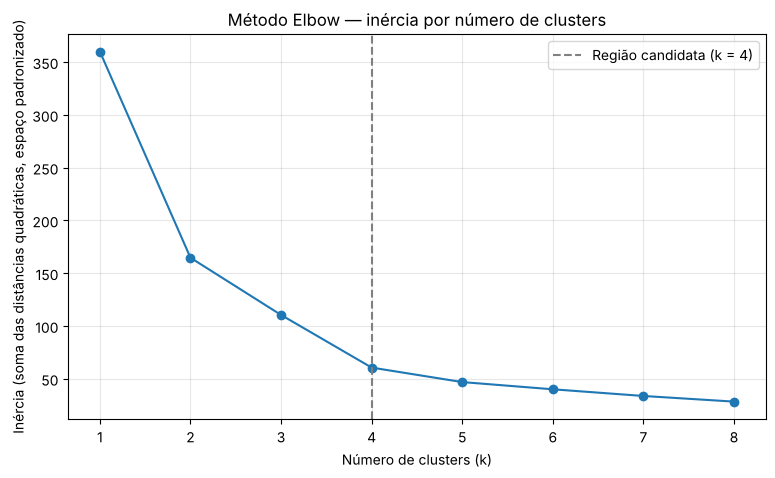

In [7]:
valores_k = range(1, 9)
distorcoes = []
for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    modelo.fit(X_padronizado)
    distorcoes.append(modelo.inertia_)

tabela_elbow = pd.DataFrame({'k': list(valores_k), 'inercia': distorcoes})
tabela_elbow['queda_em_relacao_ao_k_anterior'] = -tabela_elbow['inercia'].diff()
tabela_elbow['queda_percentual'] = tabela_elbow['queda_em_relacao_ao_k_anterior'] / tabela_elbow['inercia'].shift() * 100
print(tabela_elbow.round(2).to_string(index=False))

plt.plot(list(valores_k), distorcoes, marker='o')
plt.axvline(4, color='gray', linestyle='--', label='Região candidata (k = 4)')
plt.title('Método Elbow — inércia por número de clusters')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inércia (soma das distâncias quadráticas, espaço padronizado)')
plt.xticks(list(valores_k))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Leitura do Elbow:**

As inércias calculadas foram **360,00 (k=1), 164,71 (k=2), 110,52 (k=3), 60,65 (k=4), 46,92 (k=5), 40,08 (k=6), 33,75 (k=7) e 28,41 (k=8)**. (Com dados padronizados, a inércia com k=1 é igual a n × número de variáveis = 120 × 3 = 360.)

- De 1 para 2 grupos a queda é grande (−195,29, ou 54%).
- De 2 para 3 a queda é menor (−54,19), mas de **3 para 4 a queda volta a ser grande (−49,87, ou 45% da inércia de k=3)**.
- **A partir de k=4 as quedas ficam pequenas e parecidas**: −13,73 (5), −6,84 (6), −6,33 (7) e −5,34 (8).

A **região candidata é k = 4**: é o último ponto em que acrescentar um grupo reduz bastante a inércia. Depois dele, cada novo cluster traz um ganho pequeno, o que sugere que os grupos adicionais estariam apenas dividindo grupos já compactos. O cotovelo é razoavelmente nítido, mas o Elbow sozinho não garante a escolha, por isso ele é comparado com o Silhouette Score na próxima seção.


## Apoio: Silhouette Score

Para cada ponto, compara-se a distância média aos demais pontos do seu grupo, $a$, com a menor distância média a outro grupo, $b$:

$$s=\frac{b-a}{\max(a,b)}$$

O **Silhouette Score** é a média dos valores individuais. Para um grupo com um único ponto, adota-se score individual zero.

- Próximo de **1**: grupos compactos e separados segundo as distâncias utilizadas.
- Próximo de **0**: sobreposição ou pontos perto das fronteiras.
- **Negativo**: pontos, em média, mais próximos de outro grupo.

Se $a=2$ e $b=8$, o valor individual é 0,75. Isso **não significa 75% de acertos**: não existe comparação com classes corretas. Não há um limiar universal que valide qualquer agrupamento.

O cálculo exige entre 2 e $n-1$ grupos distintos. Por isso, k = 1 participa do Elbow, mas não da comparação de Silhouette Score. A média pode esconder situações diferentes dentro de cada grupo.


## 5. Comparação por Silhouette Score — 1,5 ponto

Teste **k de 2 a 8**, mantendo `random_state=42` e `n_init=10`. Para cada k, obtenha os rótulos e calcule `silhouette_score(X_padronizado, rotulos)`.

Apresente uma tabela com k e score, além de um gráfico com esses valores. Identifique o maior score do intervalo testado e compare-o com a indicação do Elbow. Se houver divergência, explique-a e justifique sua decisão considerando também a interpretação dos perfis.

Não adicione a coluna de clusters a `X_padronizado` para calcular a métrica. Isso alteraria as distâncias que você pretende avaliar.


 k  silhouette_score
 2            0.4842
 3            0.4889
 4            0.5526
 5            0.5433
 6            0.5037
 7            0.4644
 8            0.4771

Maior Silhouette Score: k = 4 (score = 0.5526)


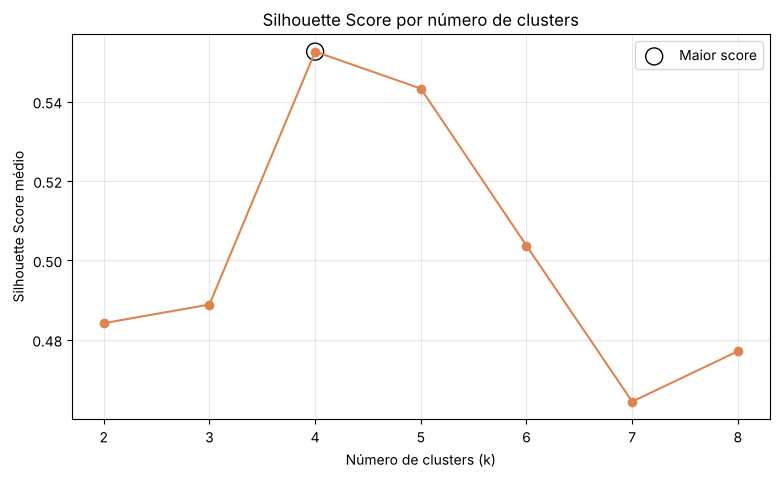

In [8]:
resultados_silhouette = []
for k in range(2, 9):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    rotulos = modelo.fit_predict(X_padronizado)
    resultados_silhouette.append({'k': k, 'silhouette_score': silhouette_score(X_padronizado, rotulos)})

tabela_silhouette = pd.DataFrame(resultados_silhouette)
print(tabela_silhouette.round(4).to_string(index=False))
melhor = tabela_silhouette.loc[tabela_silhouette['silhouette_score'].idxmax()]
print(f"\nMaior Silhouette Score: k = {int(melhor['k'])} (score = {melhor['silhouette_score']:.4f})")

plt.plot(tabela_silhouette['k'], tabela_silhouette['silhouette_score'], marker='o', color='#DD8452')
plt.scatter([melhor['k']], [melhor['silhouette_score']], s=150, facecolors='none', edgecolors='black', label='Maior score')
plt.title('Silhouette Score por número de clusters')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Silhouette Score médio')
plt.xticks(range(2, 9))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Comparação das evidências:**

| k | 2 | 3 | **4** | 5 | 6 | 7 | 8 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Silhouette | 0,4842 | 0,4889 | **0,5526** | 0,5433 | 0,5037 | 0,4644 | 0,4771 |

- O **maior Silhouette Score é 0,5526, com k = 4**. É o ponto em que, em média, os clientes estão mais próximos do próprio grupo e mais distantes do grupo vizinho.
- **Elbow e Silhouette concordam**: os dois indicam k = 4. Não há divergência a resolver.
- k = 5 tem score próximo (0,5433), mas um pouco menor, e o Elbow mostra que o 5º grupo reduz a inércia em apenas 13,73. Ou seja, ele divide um grupo existente sem ganho claro de separação.
- k = 2 e k = 3 têm scores mais baixos (≈ 0,48–0,49). Com k = 3, um mesmo grupo junta clientes que gastaram de R$ 420 a R$ 9.299 com poucas compras e muitos dias sem comprar, misturando clientes de baixo valor com clientes de compras grandes e esporádicas, que pedem ações diferentes.
- Um score de 0,55 indica uma estrutura de grupos razoável, com alguma sobreposição nas fronteiras. Não é uma porcentagem de acerto.


## 6. Escolha de k e agrupamento final — 1,0 ponto

Defina `k_escolhido`, ajuste o modelo final sobre `X_padronizado` e crie `df_resultados` como uma cópia de `df`, acrescentando a coluna `cluster`.

Apresente a quantidade de clientes por grupo e o Silhouette Score final. Justifique k com base nas etapas anteriores. Os números dos clusters são apenas identificadores: cluster 2 não é necessariamente maior ou melhor que cluster 0.


In [9]:
k_escolhido = 4

modelo_final = KMeans(n_clusters=k_escolhido, random_state=42, n_init=10)
rotulos_finais = modelo_final.fit_predict(X_padronizado)

df_resultados = df.copy()
df_resultados['cluster'] = rotulos_finais

print("Clientes por cluster:")
print(df_resultados['cluster'].value_counts().sort_index().to_string())
print(f"\nSilhouette Score final (k = {k_escolhido}): {silhouette_score(X_padronizado, rotulos_finais):.4f}")

# Centroides convertidos de volta para as unidades originais
centroides = pd.DataFrame(scaler.inverse_transform(modelo_final.cluster_centers_), columns=variaveis)
centroides.index.name = 'cluster'
centroides.round(1)

Clientes por cluster:
cluster
0    28
1    30
2    32
3    30

Silhouette Score final (k = 4): 0.5526


,gasto_total_12_meses,quantidade_compras_12_meses,dias_desde_ultima_compra
cluster,,,
0,9309.6,27.1,10.5
1,6741.4,6.3,75.6
2,2861.7,22.7,15.0
3,833.3,4.1,102.4


**k escolhido e justificativa:**

**k_escolhido = 4**, por três evidências que apontam para o mesmo valor:

1. **Elbow:** k = 4 é o cotovelo. A queda de 3 para 4 foi de 49,87 e as seguintes ficam entre 5 e 14.
2. **Silhouette:** k = 4 tem o maior score do intervalo testado (0,5526).
3. **Interpretação:** os 4 grupos são equilibrados (28, 30, 32 e 30 clientes), nenhum é minúsculo ou dominante, e cada um tem uma combinação diferente de gasto, frequência e recência, como mostram os centroides acima. Isso permite uma ação de relacionamento distinta para cada grupo (seção 7).

O score final do modelo (0,5526) é o mesmo da comparação, já que foram usados os mesmos parâmetros (`random_state=42`, `n_init=10`). Os números 0 a 3 são apenas identificadores dos grupos.


## 7. Visualização e interpretação — 2,0 pontos

Construa dois gráficos de dispersão, usando as cores para identificar os clusters:

1. Gasto total nos últimos 12 meses × quantidade de compras nos últimos 12 meses.
2. Gasto total nos últimos 12 meses × dias desde a última compra.

Use valores nas unidades originais, títulos, unidades nos eixos e uma legenda que identifique os grupos. Os gráficos mostram projeções em duas dimensões; o modelo utilizou três variáveis.

Crie uma tabela com a quantidade de clientes e as médias das três variáveis por cluster, nas unidades originais. Descreva cada perfil usando esses números e proponha uma ação de relacionamento para cada um. Diferencie o que os dados mostram do que ainda precisaria ser investigado.

Gasto alto não comprova renda elevada nem satisfação. Muitos dias sem comprar não comprovam que o cliente abandonou a empresa. Uma ação de reativação, fidelização ou oferta direcionada deve ser apresentada como hipótese, com os dados adicionais necessários para avaliá-la.


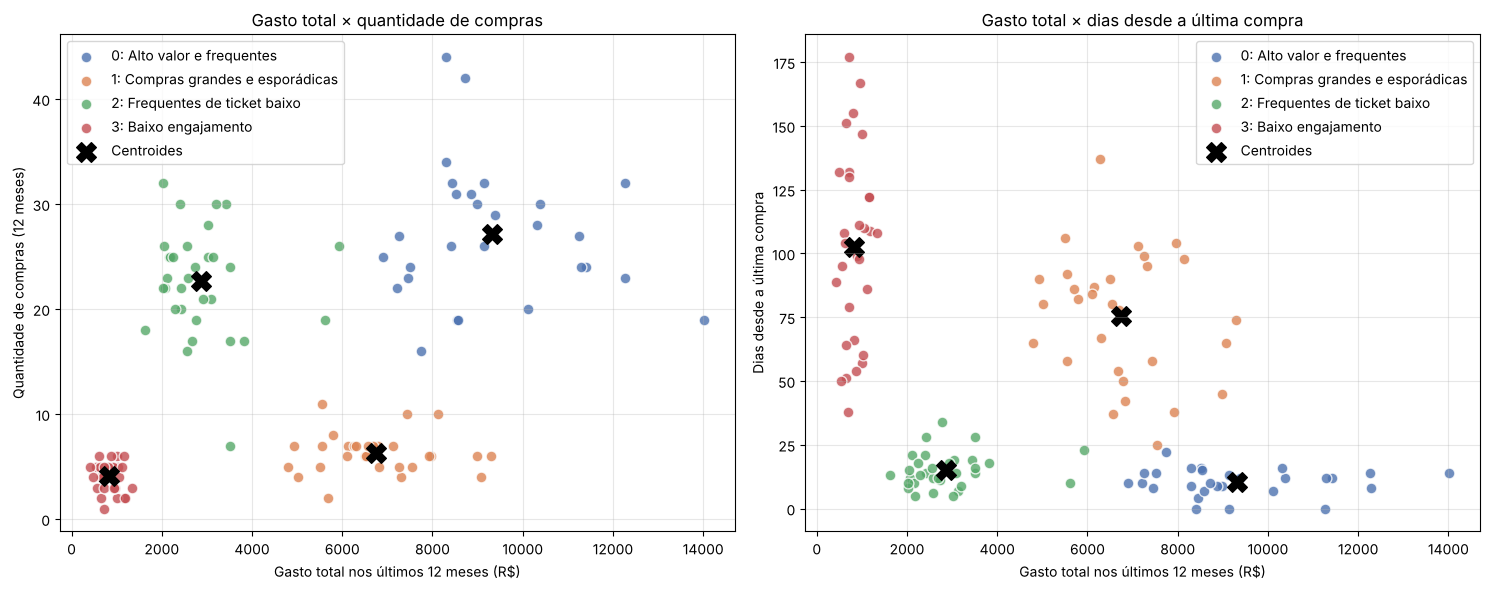

In [10]:
nomes_clusters = {
    0: '0: Alto valor e frequentes',
    1: '1: Compras grandes e esporádicas',
    2: '2: Frequentes de ticket baixo',
    3: '3: Baixo engajamento',
}
cores = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

fig, eixos = plt.subplots(1, 2, figsize=(15, 6))
pares = [
    ('quantidade_compras_12_meses', 'Quantidade de compras (12 meses)', 'Gasto total × quantidade de compras'),
    ('dias_desde_ultima_compra', 'Dias desde a última compra', 'Gasto total × dias desde a última compra'),
]
for eixo, (coluna_y, rotulo_y, titulo) in zip(eixos, pares):
    for c in sorted(df_resultados['cluster'].unique()):
        grupo = df_resultados[df_resultados['cluster'] == c]
        eixo.scatter(grupo['gasto_total_12_meses'], grupo[coluna_y], color=cores[c], label=nomes_clusters[c], alpha=0.8, edgecolor='white', s=60)
    eixo.scatter(centroides['gasto_total_12_meses'], centroides[coluna_y], marker='X', s=200, color='black', label='Centroides')
    eixo.set_title(titulo)
    eixo.set_xlabel('Gasto total nos últimos 12 meses (R$)')
    eixo.set_ylabel(rotulo_y)
    eixo.grid(alpha=0.3)
    eixo.legend()
plt.tight_layout()
plt.show()

In [11]:
perfil = df_resultados.groupby('cluster').agg(
    clientes=('id_cliente', 'count'),
    gasto_medio=('gasto_total_12_meses', 'mean'),
    gasto_min=('gasto_total_12_meses', 'min'),
    gasto_max=('gasto_total_12_meses', 'max'),
    compras_media=('quantidade_compras_12_meses', 'mean'),
    compras_min=('quantidade_compras_12_meses', 'min'),
    compras_max=('quantidade_compras_12_meses', 'max'),
    dias_medio=('dias_desde_ultima_compra', 'mean'),
    dias_min=('dias_desde_ultima_compra', 'min'),
    dias_max=('dias_desde_ultima_compra', 'max'),
)
perfil['ticket_medio'] = perfil['gasto_medio'] / perfil['compras_media']
perfil['participacao_no_gasto_%'] = df_resultados.groupby('cluster')['gasto_total_12_meses'].sum() / df_resultados['gasto_total_12_meses'].sum() * 100
perfil.round(1)

,clientes,gasto_medio,gasto_min,gasto_max,compras_media,compras_min,compras_max,dias_medio,dias_min,dias_max,ticket_medio,participacao_no_gasto_%
cluster,,,,,,,,,,,,
0,28,9309.6,6896.3,14019.6,27.1,16,44,10.5,0,22,343.4,45.0
1,30,6741.4,4788.0,9298.7,6.3,2,11,75.6,25,137,1064.4,34.9
2,32,2861.7,1625.9,5923.8,22.7,7,32,15.0,5,34,126.3,15.8
3,30,833.3,420.0,1339.6,4.1,1,6,102.4,38,177,204.9,4.3


**Interpretação dos perfis e ações propostas:**

| Cluster | Evidências numéricas e perfil | Ação proposta | Informação adicional necessária |
| --- | --- | --- | --- |
| **0: Alto valor e frequentes** (28 clientes) | Maior gasto médio (**R$ 9.309,6**; de R$ 6.896 a R$ 14.020), maior frequência (**27,1 compras**, de 16 a 44) e compras muito recentes (**10,5 dias**, máximo 22). Representa **45% de todo o gasto** da base com 23% dos clientes. Ticket médio ≈ R$ 343. | **Fidelização:** programa VIP ou de pontos, acesso antecipado a lançamentos e atendimento prioritário. O objetivo é manter a frequência, não dar desconto a quem já compra. | Margem de lucro por cliente (gasto alto não garante lucro), satisfação/NPS, devoluções e se o cliente também compra na concorrência. |
| **1: Compras grandes e esporádicas** (30 clientes) | Gasto médio alto (**R$ 6.741,4**), mas com poucas compras (**6,3**, de 2 a 11), ou seja, o **maior ticket médio (≈ R$ 1.064)**. Estão há **75,6 dias** em média sem comprar (de 25 a 137). Somam 34,9% do gasto. | **Reativação direcionada (hipótese):** recomendações e ofertas ligadas ao tipo de produto que já compraram, lembrete no ciclo de recompra esperado e frete grátis em compras de valor alto. | Categorias compradas (produtos duráveis têm recompra naturalmente lenta), ciclo de recompra típico, resposta a campanhas anteriores e se a demora é sazonal ou sinal de perda. |
| **2: Frequentes de ticket baixo** (32 clientes) | Compram com frequência (**22,7 compras**, de 7 a 32) e recentemente (**15,0 dias**, máximo 34), mas com gasto moderado (**R$ 2.861,7**), o que dá o **menor ticket médio (≈ R$ 126)**. | **Aumento de ticket (hipótese):** cross-sell e up-sell, kits/combos, frete grátis a partir de um valor mínimo e recomendações de produtos complementares. São clientes engajados que podem gastar mais por compra. | Categorias e margem dos itens comprados, sensibilidade a preço, uso de cupons e se o cliente tem capacidade/interesse de comprar itens mais caros. |
| **3: Baixo engajamento / possivelmente inativos** (30 clientes) | Menor gasto (**R$ 833,3**, máximo R$ 1.340), poucas compras (**4,1**, de 1 a 6) e a maior recência (**102,4 dias**, até 177). Somam só 4,3% do gasto. | **Reativação de baixo custo (hipótese):** campanha automatizada por e-mail com cupom de retorno, pesquisa curta sobre o motivo de não comprarem e testes A/B para medir o retorno antes de investir mais. | Motivo do afastamento (preço, entrega, atendimento), se são clientes novos ou antigos, custo de aquisição/reativação e se o cliente ainda aceita receber comunicações. |

**O que os dados mostram e o que ainda precisa ser investigado:** os números mostram apenas **quanto**, **quantas vezes** e **há quanto tempo** cada cliente comprou. Eles **não comprovam** que o cluster 0 está satisfeito ou tem renda alta, nem que os clusters 1 e 3 abandonaram a empresa: muitos dias sem comprar podem ser normais para quem compra produtos duráveis. Por isso as ações acima são **hipóteses**, que devem ser testadas (por exemplo, com grupos de controle) e avaliadas com os dados adicionais da última coluna.

Os gráficos são projeções em 2 dimensões. No segundo (gasto × dias), os clusters 0 e 2 ficam na mesma faixa de recência (todos compraram há pouco tempo) e só se distinguem pelo gasto. O primeiro (gasto × compras) mostra que eles também diferem na frequência. Já os clusters 1 e 3 compram pouco e estão há mais tempo sem comprar, mas ficam em extremos opostos do gasto. Nenhuma variável sozinha separa os quatro grupos, por isso o modelo usou as três juntas.


## 8. Conclusão — 1,5 ponto

Responda com base nos seus resultados:

1. Como o agrupamento ajuda a empresa a compreender os perfis de compra?
2. Por que o menor valor de inércia, isoladamente, não resolve a escolha de k?
3. Por que Silhouette Score não é uma medida de acurácia?
4. Por que é necessário separar as variáveis usadas no modelo da coluna `cluster`?
5. Apresente pelo menos duas limitações: uma sobre a base simulada e outra sobre os dados disponíveis ou o K-Means. Que dados reais você buscaria para aprimorar a análise?

**Conclusão:**

**1. Como o agrupamento ajuda a empresa.** O K-Means com k = 4 dividiu os 120 clientes em quatro perfis claros, combinando gasto, frequência e recência: clientes de **alto valor e frequentes** (28, 45% do gasto), de **compras grandes e esporádicas** (30, maior ticket, ≈ R$ 1.064), **frequentes de ticket baixo** (32, ≈ R$ 126 por compra) e de **baixo engajamento** (30, 4,3% do gasto, 102 dias sem comprar em média). Em vez de uma comunicação única para todos, a empresa pode priorizar recursos (fidelizar quem gera a maior parte da receita, aumentar o ticket de quem já é frequente e testar a reativação dos demais) e medir o resultado de cada ação por grupo.

**2. Por que a menor inércia não resolve a escolha de k.** A inércia **sempre diminui** quando k aumenta: com k = 8 ela é 28,41, e com k = 120 (um grupo por cliente) seria zero. Escolher o menor valor levaria sempre ao maior k testado, com grupos pequenos demais para gerar ações úteis. O que importa é **onde o ganho deixa de compensar**: aqui, depois de k = 4 as quedas caem para 13,73 ou menos. Por isso a decisão combinou o Elbow com o Silhouette e com a interpretação dos perfis.

**3. Por que o Silhouette não é acurácia.** Acurácia compara previsões com respostas corretas conhecidas, e **nesta base não existe uma coluna com a classificação correta**. O Silhouette mede apenas a **geometria** dos grupos: o quanto cada ponto está mais próximo do próprio cluster do que do vizinho, nas distâncias do espaço padronizado. O score de 0,5526 indica grupos razoavelmente separados, não "55% de acerto". Um agrupamento com bom score pode ainda ser pouco útil para o negócio, e o score muda se mudarem as variáveis ou a padronização.

**4. Por que separar as variáveis do modelo da coluna `cluster`.** O rótulo `cluster` é **resultado** do modelo, não uma característica do cliente. Se ele entrasse em `X_padronizado`, passaria a fazer parte das distâncias: clientes do mesmo grupo ficariam artificialmente mais próximos, o Silhouette seria inflado e um novo ajuste tenderia a só repetir os grupos anteriores (um raciocínio circular). Por isso os rótulos foram guardados apenas em `df_resultados`, uma cópia de `df`, e as métricas foram calculadas com as três variáveis originais padronizadas.

**5. Limitações e dados para aprimorar a análise.**
- **Base simulada:** os 120 clientes foram gerados com NumPy (semente 303) para fins didáticos. Os grupos podem ser mais "limpos" que os de clientes reais, e a amostra é pequena. Os resultados servem para praticar o método, não para tomar decisões em uma empresa real.
- **Dados disponíveis:** há apenas três variáveis de comportamento (gasto, frequência e recência). Elas não informam margem de lucro, categorias compradas, canal, satisfação, devoluções, renda ou o motivo de o cliente parar de comprar. Por isso os perfis descrevem **o que** o cliente fez, mas não **por quê**.
- **K-Means:** o algoritmo supõe grupos aproximadamente esféricos e de tamanho parecido, é sensível a outliers (por exemplo, o cliente CL014, com R$ 14.019,61) e à inicialização (controlada com `random_state=42` e `n_init=10`), e exige escolher k previamente. A recência também é uma "foto" de uma única data de referência.
- **Dados reais que buscaríamos:** histórico de pedidos com datas e categorias, margem por produto, ticket por pedido, tempo de cliente (data da primeira compra), canal de aquisição, uso de cupons, devoluções, NPS/avaliações, interações com campanhas (abertura e cliques em e-mails) e região. Com esses dados seria possível validar os perfis ao longo do tempo, testar as ações com grupos de controle e comparar o K-Means com outros métodos (por exemplo, DBSCAN ou clustering hierárquico).


## Entrega e critérios de avaliação

Envie na tarefa do Teams **apenas o link do repositório GitHub**, contendo:

- **Notebook Python (`.ipynb`) preenchido e executado**, com identificação, códigos, tabelas, gráficos, justificativas e conclusões.
- **README.md explicativo**, com nome e RM dos integrantes, objetivo da atividade, descrição da base de dados, orientações para executar o notebook e principais resultados encontrados.

O repositório deverá estar acessível ao professor para avaliação. A base está incorporada ao notebook; não é necessário um arquivo externo para executar a atividade. O prazo será informado na tarefa do Teams.

| Critério | Pontos |
| --- | ---: |
| Exploração e compreensão dos dados | 1,0 |
| Seleção das variáveis e padronização justificada | 1,5 |
| Elbow: implementação, gráfico e leitura | 1,5 |
| Silhouette Score: comparação, gráfico e interpretação | 1,5 |
| Modelo final e justificativa de k | 1,0 |
| Visualizações, perfis e ações fundamentadas | 2,0 |
| Conclusões e limitações | 1,5 |
| **Total** | **10,0** |

A avaliação considera a correção do código e a capacidade de explicar as escolhas e interpretar os resultados. Não há pontuação por apenas escolher um k específico sem justificativa.

### Antes de entregar

- Preencha nome(s), RM(s) e turma.
- Reinicie o ambiente e execute as células na ordem.
- Confira se as tabelas e os gráficos permanecem salvos no notebook.
- Verifique se usou as três variáveis e excluiu identificador e rótulos do cálculo das distâncias.
- Substitua os espaços de resposta por suas análises.
- Inclua o README.md e confira o acesso ao repositório.

### Documentação de apoio

- [K-Means e inércia — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
- [Silhouette Score — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)
- [StandardScaler — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

Atividade de Modelagem Linear para Aprendizado de Máquina, com base simulada de clientes e aplicação exploratória de clustering.
